## Logistic Regression and SVM evaluations

Team tasks **2.1** (logistic regression), **3.1** (linear SVM) and **3.2** (kernel SVM), implemented on the one-hot preprocessor from `src/preprocess.py`.

**How every model here is tuned and scored**
- **Training terms (1946-2015)** fit the model. **Validation terms (2016-2020)** pick the settings, through `PredefinedSplit` in `GridSearchCV`.
- Settings are chosen by **ROC AUC** (how well the model ranks petitioner wins above losses; 0.5 = guessing, 1.0 = perfect). We also report **balanced accuracy** (the average of the hit rate on wins and on losses; 0.5 = guessing). Both baselines score 0.50 on both, even though they reach 67.2% plain accuracy.
- `refit=False`: after the search, the best setting is refit on **training terms only**. The default refit would train on training plus validation, and then the validation score we report would be measured on data the model had seen.
- The **test terms (2021-2025) are never used here**. They are scored once, in task 4.2.

Run with **Restart -> Run All** from the `.venv` (Python 3.13) kernel. The kernel SVM section takes a few minutes.

In [1]:
import sys
from pathlib import Path

# make the repo root importable so `src` works from notebooks/ian/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC

from src import config
from src.data import add_circuit_features, handle_missing, load_data
from src.evaluate import evaluate
from src.features import add_features
from src.preprocess import make_onehot_preprocessor
from src.split import split_by_term

DATA_PATH = REPO_ROOT / "data" / "SCDB_2026_01_caseCentered_Citation.csv"
OWNER = "ian"
SEED = config.RANDOM_STATE  # 42

In [2]:
# Chart style, matching ian_eda.ipynb: blue = training, orange = validation, gray = context.
BLUE, ORANGE = "#2a78d6", "#eb6834"
GRAY = "#c3c2b7"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID = "#fcfcfb", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "figure.dpi": 110,
})

### 1. Load, add features, split by term, fill blanks
 `load_data` -> `add_features` -> `add_circuit_features` -> `split_by_term` -> `handle_missing`.
Note: The test part is thrown away on purpose (`_`), so it can't be used by accident.

In [3]:
cases = load_data(DATA_PATH)
cases = add_circuit_features(add_features(cases))

X_train, y_train, X_val, y_val, _, _ = split_by_term(cases, config.FEATURE_COLUMNS)

# handle_missing drops nothing here (X only holds feature columns) and fills blanks with -1
X_train = handle_missing(X_train)
X_val = handle_missing(X_val)

assert (len(X_train), len(X_val)) == (7611, 305), "split sizes differ from CLAUDE.local.md"
print(f"\n{X_train.shape[1]} feature columns, e.g. {list(X_train.columns[:5])} ...")

Number of rows loaded: 9,409
Number of rows after decisionType filter: 8,216
Number of rows after partyWinning filter: 8,211
train: 7,611 cases, terms 1946-2015, petitioner win rate 62.8%
  val:   305 cases, terms 2016-2020, petitioner win rate 67.2%
 test:   295 cases, terms 2021-2025, petitioner win rate 69.2%

21 feature columns, e.g. ['naturalCourt', 'petitioner', 'respondent', 'jurisdiction', 'adminAction'] ...


### 2. Shared Grid Search

`GridSearchCV` normally shuffles data into folds, but here, `PredefinedSplit` uses one fixed fold: rows marked `-1` (training terms) are always used to fit, rows marked `0` (validation terms) are always used to score.

In [4]:
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])
fold = np.concatenate([np.full(len(X_train), -1), np.zeros(len(X_val), dtype=int)])
validation_fold = PredefinedSplit(fold)

SCORING = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy"}
SCORE_COLUMNS = ["train_roc_auc", "val_roc_auc", "train_bal_acc", "val_bal_acc", "gap_roc_auc"]

n_inputs = make_onehot_preprocessor().fit(X_train).transform(X_train).shape[1]
print(f"search data: {len(X_search):,} rows; the one-hot preprocessor turns "
      f"{X_train.shape[1]} columns into {n_inputs} model inputs")


def search(model, grid):
    """Try every setting in `grid`: fit on training terms, score on validation terms.
    
    Docs---
    model: an unfitted scikit-learn classifier.
    grid: {"model__<setting>": [values to try]}.
    Returns a table with one row per setting and its training and validation scores,
    best validation ROC AUC first. gap_roc_auc = training minus validation (big gap = overfitting).
    """
    pipeline = Pipeline([("prep", make_onehot_preprocessor()), ("model", model)])
    grid_search = GridSearchCV(pipeline, grid, cv=validation_fold, scoring=SCORING,
                               refit=False, return_train_score=True, n_jobs=-1)
    grid_search.fit(X_search, y_search)

    raw = pd.DataFrame(grid_search.cv_results_)
    table = pd.DataFrame(list(raw["params"]))
    table.columns = [name.removeprefix("model__") for name in table.columns]
    table["train_roc_auc"] = raw["mean_train_roc_auc"]
    table["val_roc_auc"] = raw["mean_test_roc_auc"]
    table["train_bal_acc"] = raw["mean_train_balanced_accuracy"]
    table["val_bal_acc"] = raw["mean_test_balanced_accuracy"]
    table["gap_roc_auc"] = table["train_roc_auc"] - table["val_roc_auc"]
    return table.sort_values("val_roc_auc", ascending=False)


def fit_best(model, table):
    """Refit `model` with the top setting in `table` on training terms only.

    Returns the fitted pipeline and the chosen settings as a dict.
    """
    best = table.iloc[0].drop(SCORE_COLUMNS).to_dict()
    best = {name: (value.item() if hasattr(value, "item") else value) for name, value in best.items()}
    pipeline = Pipeline([("prep", make_onehot_preprocessor()), ("model", model.set_params(**best))])
    pipeline.fit(X_train, y_train)
    return pipeline, best


def bootstrap_interval(y_true, y_score, y_pred, n=1000, seed=SEED):
    """95% bootstrap intervals for validation ROC AUC and balanced accuracy.

    Resamples the 305 validation cases with replacement `n` times and keeps the middle 95%
    of the scores, to show how much of a difference could be luck of the sample.
    """
    rng = np.random.default_rng(seed)
    y_true, y_score, y_pred = map(np.asarray, (y_true, y_score, y_pred))
    auc, bal = [], []
    for _ in range(n):
        pick = rng.integers(0, len(y_true), len(y_true))
        auc.append(roc_auc_score(y_true[pick], y_score[pick]))
        bal.append(balanced_accuracy_score(y_true[pick], y_pred[pick]))
    return np.percentile(auc, [2.5, 97.5]), np.percentile(bal, [2.5, 97.5])


def score_and_log(name, pipeline, params):
    """Score a fitted pipeline on validation terms, log it with evaluate(), and print the result."""
    model = pipeline.named_steps["model"]
    y_pred = pipeline.predict(X_val)
    # ROC AUC needs a "how sure" number: probabilities for logistic regression, distances for SVMs
    if hasattr(model, "predict_proba"):
        y_score = pipeline.predict_proba(X_val)[:, 1]
    else:
        y_score = pipeline.decision_function(X_val)
    scores = evaluate(name, params, y_val, y_pred, y_score, owner=OWNER, split="val")
    auc_ci, bal_ci = bootstrap_interval(y_val, y_score, y_pred)
    scores["roc_auc_ci"], scores["bal_acc_ci"] = auc_ci, bal_ci
    print(f"{name} {params}\n"
          f"  accuracy           {scores['accuracy']:.1%}   (baselines 67.2%)\n"
          f"  balanced accuracy  {scores['balanced_accuracy']:.3f}   95% interval {bal_ci[0]:.3f}-{bal_ci[1]:.3f}   (baselines 0.500)\n"
          f"  ROC AUC            {scores['roc_auc']:.3f}   95% interval {auc_ci[0]:.3f}-{auc_ci[1]:.3f}   (baselines 0.500)\n"
          f"  confusion counts   tn={scores['tn']} fp={scores['fp']} fn={scores['fn']} tp={scores['tp']}")
    return scores


def plot_fit(ax, table, setting, chosen, title):
    """Training vs validation ROC AUC across one setting (log scale): the fit picture."""
    table = table.sort_values(setting)
    ax.plot(table[setting], table["train_roc_auc"], color=BLUE, marker="o", markersize=5, label="training terms")
    ax.plot(table[setting], table["val_roc_auc"], color=ORANGE, marker="o", markersize=5, label="validation terms")
    ax.set_xscale("log")
    ax.axhline(0.5, color=MUTED, linewidth=1, zorder=0.9)
    ax.text(table[setting].min(), 0.5, " baselines (0.50)", color=INK_2, fontsize=9, va="bottom")
    ax.axvline(chosen, color=MUTED, linewidth=1, linestyle=":", zorder=0.9)
    ax.text(chosen, 1.0, " chosen", transform=ax.get_xaxis_transform(), color=INK_2, fontsize=9, va="bottom")
    last = table.iloc[-1]
    for column, text in [("train_roc_auc", "training"), ("val_roc_auc", "validation")]:
        ax.annotate(text, (last[setting], last[column]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK_2, fontsize=9)
    ax.set_xlabel(f"{setting}  (left = simpler model, right = more complex)")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)

search data: 7,916 rows; the one-hot preprocessor turns 21 columns into 747 model inputs


### 3. Logistic regression (task 2.1)

`C` controls how much the model may bend to the training data. Small `C` = strong regularization (a penalty that keeps the weights small, so the model stays simple); large `C` = weak regularization.

`class_weight="balanced"` counts each losing case a bit more, since 63% of training cases are petitioner wins. The grid tries it with and without.

In [5]:
LR_GRID = {
    "model__C": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}
lr_model = LogisticRegression(max_iter=5000, random_state=SEED)
lr_table = search(lr_model, LR_GRID)
display(lr_table.head(8).round({c: 3 for c in SCORE_COLUMNS}))

,C,class_weight,train_roc_auc,val_roc_auc,train_bal_acc,val_bal_acc,gap_roc_auc
4,0.0010,NaN,0.634,0.616,0.511,0.505,0.019
5,0.0010,balanced,0.635,0.615,0.593,0.588,0.020
3,0.0003,balanced,0.623,0.615,0.585,0.582,0.009
2,0.0003,NaN,0.623,0.615,0.500,0.500,0.008
1,0.0001,balanced,0.617,0.613,0.582,0.575,0.005
6,0.0030,NaN,0.651,0.613,0.535,0.526,0.039
0,0.0001,NaN,0.617,0.613,0.500,0.500,0.005
7,0.0030,balanced,0.653,0.612,0.610,0.582,0.041


Rows with the same `C` have almost the same ROC AUC with or without `"balanced"`, because weighting barely changes the *ranking* of cases. It does change the 0/1 predictions: without it the model says "petitioner wins" for nearly every case, like the baseline, and balanced accuracy stays near 0.5. So we keep `"balanced"` and pick `C` by ROC AUC among those rows.

In [6]:
lr_balanced = lr_table[lr_table["class_weight"] == "balanced"]
lr_pipeline, lr_params = fit_best(lr_model, lr_balanced)
lr_scores = score_and_log("logistic regression", lr_pipeline, lr_params)

logistic regression {'C': 0.001, 'class_weight': 'balanced'}
  accuracy           63.9%   (baselines 67.2%)
  balanced accuracy  0.588   95% interval 0.529-0.647   (baselines 0.500)
  ROC AUC            0.615   95% interval 0.545-0.683   (baselines 0.500)
  confusion counts   tn=44 fp=56 fn=54 tp=151


### 4. Linear SVM (task 3.1)

Note log: `LinearSVC` draws the same kind of straight dividing line as logistic regression, with a different loss (focuses on the cases near the line). `C` means the same thing. SVMs give no probabilities, so ROC AUC uses `decision_function` (how far, and on which side of the line, each case falls).

In [7]:
SVM_GRID = {
    "model__C": [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.1, 1],
    "model__class_weight": ["balanced"],
}
svm_model = LinearSVC(max_iter=20000, random_state=SEED)
svm_table = search(svm_model, SVM_GRID)
display(svm_table.head(5).round({c: 3 for c in SCORE_COLUMNS}))

svm_pipeline, svm_params = fit_best(svm_model, svm_table)
svm_scores = score_and_log("linear svm", svm_pipeline, svm_params)

,C,class_weight,train_roc_auc,val_roc_auc,train_bal_acc,val_bal_acc,gap_roc_auc
1,0.00003,balanced,0.622,0.615,0.582,0.583,0.007
2,0.00010,balanced,0.632,0.615,0.590,0.591,0.018
3,0.00030,balanced,0.649,0.614,0.605,0.584,0.035
0,0.00001,balanced,0.617,0.612,0.580,0.580,0.004
4,0.00100,balanced,0.675,0.608,0.625,0.572,0.067


linear svm {'C': 3e-05, 'class_weight': 'balanced'}
  accuracy           65.6%   (baselines 67.2%)
  balanced accuracy  0.583   95% interval 0.529-0.639   (baselines 0.500)
  ROC AUC            0.615   95% interval 0.546-0.683   (baselines 0.500)
  confusion counts   tn=37 fp=63 fn=42 tp=163


### 5. Good fit, overfitting or underfitting?

Each chart shows the score on the data the model learned from (training terms) and on new data (validation terms) as `C` grows.
- **Both lines low and close together** -> underfitting (the model is too simple to pick up the pattern).
- **Training keeps rising while validation falls** -> overfitting (the model memorizes the training terms).
- The best setting is where validation peaks.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


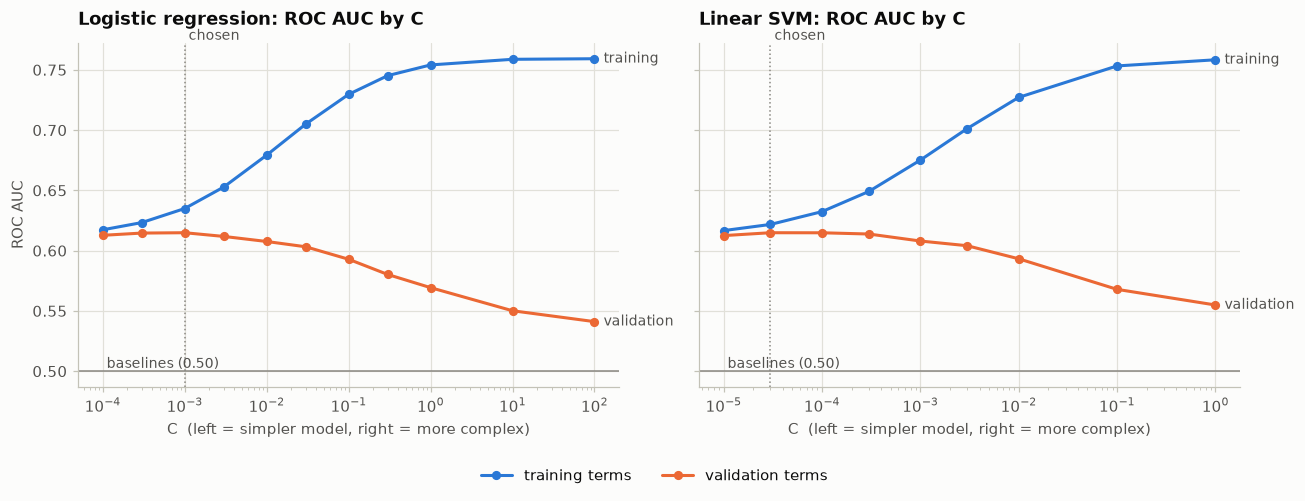

logistic regression:
  chosen  C=0.001    train 0.635  val 0.615  gap 0.020
  largest C=100.0    train 0.759  val 0.541  gap 0.218
linear svm:
  chosen  C=3e-05    train 0.622  val 0.615  gap 0.007
  largest C=1.0      train 0.758  val 0.555  gap 0.203


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
plot_fit(axes[0], lr_balanced, "C", lr_params["C"], "Logistic regression: ROC AUC by C")
plot_fit(axes[1], svm_table, "C", svm_params["C"], "Linear SVM: ROC AUC by C")
axes[1].set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncols=2, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

for name, table, params in [("logistic regression", lr_balanced, lr_params), ("linear svm", svm_table, svm_params)]:
    chosen = table[table["C"] == params["C"]].iloc[0]
    biggest = table.sort_values("C").iloc[-1]
    print(f"{name}:\n"
          f"  chosen  C={params['C']:<7}  train {chosen['train_roc_auc']:.3f}  val {chosen['val_roc_auc']:.3f}  gap {chosen['gap_roc_auc']:.3f}\n"
          f"  largest C={biggest['C']:<7}  train {biggest['train_roc_auc']:.3f}  val {biggest['val_roc_auc']:.3f}  gap {biggest['gap_roc_auc']:.3f}")

### 6. What logistic regression learned

The largest weights, after one-hot encoding. Positive weights push toward "petitioner wins", negative toward "petitioner loses". Names read `column = code`; look codes up in the SCDB codebook (for example, party code 27 = United States).

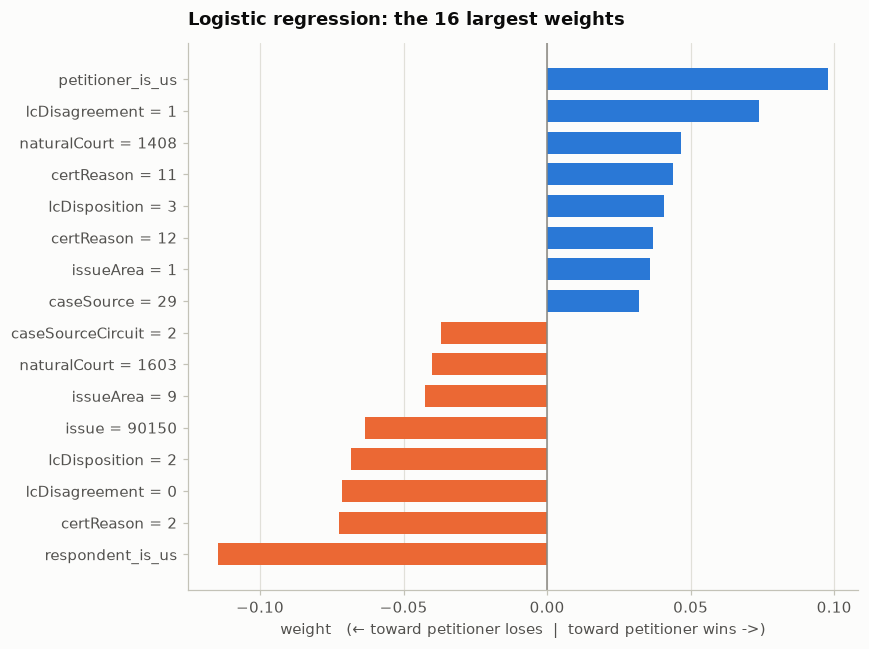

In [9]:
names = lr_pipeline.named_steps["prep"].get_feature_names_out()
weights = pd.Series(lr_pipeline.named_steps["model"].coef_[0], index=names)
category_columns = sorted(config.CATEGORICAL_FEATURES + config.DERIVED_CATEGORICAL_FEATURES, key=len, reverse=True)


def readable(name):
    """'categorical__petitioner_27.0' -> 'petitioner = 27'; 'numeric__term' -> 'term'."""
    kind, rest = name.split("__", 1)
    if kind == "numeric":
        return rest
    for column in category_columns:  # longest first, so 'caseSourceCircuit' wins over 'caseSource'
        if rest.startswith(column + "_"):
            code = rest[len(column) + 1:].removesuffix(".0")
            return f"{column} = {'rare codes' if code == 'infrequent_sklearn' else code}"
    return rest


weights.index = [readable(n) for n in weights.index]
top = pd.concat([weights.nsmallest(8), weights.nlargest(8).iloc[::-1]])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[BLUE if w > 0 else ORANGE for w in top.values], height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("weight   (← toward petitioner loses  |  toward petitioner wins ->)")
ax.set_title("Logistic regression: the 16 largest weights")
fig.tight_layout()
plt.show()

### 7. Kernel SVM (task 3.2, slower)

Note log: `SVC(kernel="rbf")` can draw curved boundaries. `gamma` sets how local each curve is (bigger = wigglier, easier to overfit). Each fit takes tens of seconds on about 750 inputs, so this grid is small. **This cell takes pretty long.**

In [ ]:
RBF_GRID = {
    "model__C": [0.1, 1, 10],
    "model__gamma": [0.001, "scale"],
    "model__class_weight": ["balanced"],
}
rbf_model = SVC(kernel="rbf", random_state=SEED)
rbf_table = search(rbf_model, RBF_GRID)
display(rbf_table.round({c: 3 for c in SCORE_COLUMNS}))

rbf_pipeline, rbf_params = fit_best(rbf_model, rbf_table)
rbf_scores = score_and_log("rbf svm", rbf_pipeline, rbf_params)

,C,class_weight,gamma,train_roc_auc,val_roc_auc,train_bal_acc,val_bal_acc,gap_roc_auc
0,0.1,balanced,0.001,0.613,0.612,0.542,0.563,0.002
1,0.1,balanced,scale,0.694,0.611,0.635,0.601,0.083
2,1.0,balanced,0.001,0.646,0.610,0.603,0.590,0.035
4,10.0,balanced,0.001,0.704,0.600,0.649,0.584,0.104
3,1.0,balanced,scale,0.883,0.580,0.795,0.575,0.303
5,10.0,balanced,scale,0.998,0.538,0.987,0.525,0.460


rbf svm {'C': 0.1, 'class_weight': 'balanced', 'gamma': 0.001}
  accuracy           43.3%   (baselines 67.2%)
  balanced accuracy  0.563   95% interval 0.526-0.597   (baselines 0.500)
  ROC AUC            0.612   95% interval 0.544-0.680   (baselines 0.500)
  confusion counts   tn=94 fp=6 fn=167 tp=38


### 8. Validation leaderboard so far

Note: Every number is on the 305 validation cases. When two models' 95% intervals overlap a lot, the difference between them could be luck.

In [11]:
rows = [
    {"model": "always petitioner (baseline)", "accuracy": 0.672, "balanced_accuracy": 0.5, "roc_auc": 0.5},
    {"model": "previous 10 terms (baseline)", "accuracy": 0.672, "balanced_accuracy": 0.5, "roc_auc": 0.5},
]
for scores in (lr_scores, svm_scores, rbf_scores):
    rows.append({
        "model": scores["model"],
        "accuracy": scores["accuracy"],
        "balanced_accuracy": scores["balanced_accuracy"],
        "bal_acc_95%": f"{scores['bal_acc_ci'][0]:.3f}-{scores['bal_acc_ci'][1]:.3f}",
        "roc_auc": scores["roc_auc"],
        "roc_auc_95%": f"{scores['roc_auc_ci'][0]:.3f}-{scores['roc_auc_ci'][1]:.3f}",
        "params": scores["params"],
    })
leaderboard = pd.DataFrame(rows).set_index("model")
display(leaderboard.round(3).fillna(""))
print(f"logged to {REPO_ROOT / 'results' / (OWNER + '.csv')} "
      f"(each run appends rows; delete the file before a clean rerun)")

,accuracy,balanced_accuracy,roc_auc,bal_acc_95%,roc_auc_95%,params
model,,,,,,
always petitioner (baseline),0.672,0.500,0.500,,,
previous 10 terms (baseline),0.672,0.500,0.500,,,
logistic regression,0.639,0.588,0.615,0.529-0.647,0.545-0.683,"{""C"": 0.001, ""class_weight"": ""balanced""}"
linear svm,0.656,0.583,0.615,0.529-0.639,0.546-0.683,"{""C"": 3e-05, ""class_weight"": ""balanced""}"
rbf svm,0.433,0.563,0.612,0.526-0.597,0.544-0.680,"{""C"": 0.1, ""class_weight"": ""balanced"", ""gamma""..."


logged to c:\Users\ailee\.vscode\CIS4930\Term_Project\results\ian.csv (each run appends rows; delete the file before a clean rerun)


### 9. Takeaways and next steps

_Numbers from the run on 2026-11-18. If a rerun changes them, update this cell._

**Results (validation terms, 305 cases)**
- **Logistic regression** (`C=0.001`, balanced): ROC AUC **0.615** (95% interval 0.545-0.683), balanced accuracy **0.588** (0.529-0.647), accuracy 63.9%.
- **Linear SVM** (`C=0.00003`, balanced): ROC AUC **0.615**, balanced accuracy **0.583**, accuracy 65.6%. In practice it's the same model as logistic regression.
- **Kernel SVM** (`C=0.1`, `gamma=0.001`, balanced): ROC AUC 0.612, but accuracy only 43.3%. It ranks cases as well as the others, but its yes/no cutoff is badly placed: it predicts "petitioner loses" for 261 of 305 cases.

**Against the baselines:** all three beat both baselines on ROC AUC and balanced accuracy (0.50), and the 95% intervals stay above 0.50. None beats them on **plain accuracy** (67.2%): weighting the classes trades some correct "petitioner wins" calls for correct "petitioner loses" calls. This is an honest, modest result, consistent with the Katz et al. paper, whose model also fell below the baselines in the Roberts Court.

**Fit:**
- Strong regularization (small `C`) wins.
- At the chosen `C`, training and validation are close: gap 0.020 for logistic regression and 0.007 for the linear SVM. So the fit is good, if anything slightly underfit.
- Raising `C` overfits: training ROC AUC climbs to 0.76, validation falls to 0.54-0.56, a gap above 0.2.
- The kernel SVM shows the same pattern: `C=10`, `gamma="scale"` reaches 0.99 training balanced accuracy and 0.53 validation.
- Even the training score at the chosen `C` is only about 0.63, so these case features carry limited signal on their own.

The largest weights agree with the EDA notebook:
- The United States as petitioner pushes toward a win.
- The United States as respondent pushes toward a loss.
- Lower-court disagreement (`lcDisagreement = 1`) pushes toward a win.